# Étape 2 — HEP : la réponse du cerveau au battement cardiaque

**Question** : le HEP (*heartbeat-evoked potential*, réponse EEG ~200–600 ms après chaque pic R)
change-t-il entre les vidéos à activation (arousal) **haute** et **basse** ? On regarde son amplitude
et surtout sa **latence**.

**Méthode** : pics R avec `r_peaks` (outil validé à l'étape 1) → époques EEG autour de chaque pic R,
à l'intérieur des vidéos → moyenne par condition → comparaison haute / basse, avec contrôles
de l'artefact cardiaque.

Code réutilisable : [`physio_utils.py`](physio_utils.py) (fonctions de Hugo) et [`hep_utils.py`](hep_utils.py) (HEP).
Données : variable d'environnement `HABS_DATA` (dossier contenant `CURATED/` et `labels_train.csv`).


In [1]:
import os
os.environ.setdefault("HABS_DATA", r"C:\Users\ehren\habs-data")   # à adapter sur ta machine

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from hep_utils import *
from hep_utils import TMIN, TMAX, BASELINE, HEP_WIN, LAT_WIN

SUBJ, DAYS = "P001", (1, 2)
plt.rcParams["figure.dpi"] = 90

## 1. Chargement et nettoyage

Pour chaque jour : EEG filtré 0,5–30 Hz ; électrodes plates ou très bruitées **interpolées** ;
électrodes qui **captent le pouls** interpolées aussi (voir encadré) ; référence moyenne.

ECG : le **50 Hz du secteur est retiré avant `r_peaks`**. Sans ça, sur un ECG bruité (P001 jour 2),
`r_peaks` place le pic R sur une crête du 50 Hz au lieu du vrai sommet : décalage médian de 4 ms
(jusqu'à 7 ms pour 10 % des battements) — gênant quand on mesure des latences.

> **Pourquoi chercher les électrodes « pouls » ?** Une électrode posée près d'une artère enregistre
> l'onde de pouls, qui arrive ~200–400 ms après le pic R : exactement la fenêtre du HEP, et avec une
> amplitude bien plus grande. Sur P001 jour 2, **C1** à elle seule faisait −8 µV et créait un faux
> « HEP » de −1 µV sur tout le groupe fronto-central. `pulse_channels` repère ces électrodes
> (réponse moyenne au battement > 5 écarts robustes au-dessus des autres).

In [2]:
segs = {d: load_video_session(SUBJ, d) for d in DAYS}

Channel metadata: P001_day-1_task-emotion-video_multimodal.record_map


Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.000 s


P001 jour 1 : 36 vidéos, 1246 battements (HR médiane 88 bpm) | interpolées : {'plates/bruitées': ['Fp1', 'Fp2', 'F9', 'F10', 'T10', 'AF7', 'AF8'], 'pouls': []}


Channel metadata: P001_day-2_task-emotion-video_multimodal.record_map


Gaze: stored 189 Hz, effective 188.574 Hz, onset 0.000 s


⚠️ polarité ECG ambiguë (ratio max/|min| = 1.25) : vérifier le battement moyen


P001 jour 2 : 72 vidéos, 1941 battements (HR médiane 87 bpm) | interpolées : {'plates/bruitées': ['CP1'], 'pouls': ['AF8', 'F6', 'C1']}


### Contrôle : le pic R est-il bien placé ?
Le battement moyen doit avoir un pic R net, positif, à 0 ms (un avertissement de polarité ambiguë
s'affiche pour le jour 2 : on vérifie ici à l'œil).

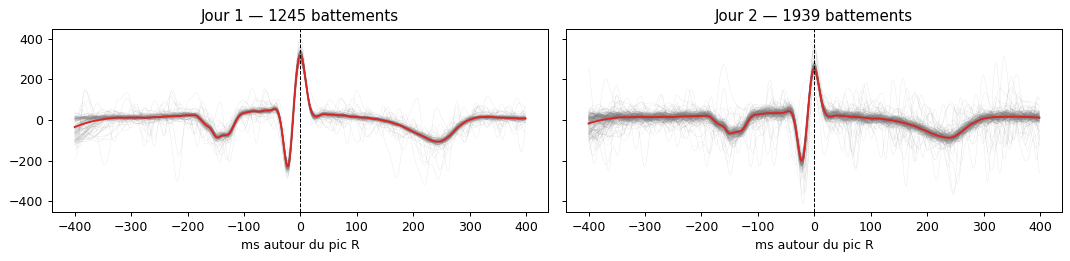

In [3]:
fig, axs = plt.subplots(1, len(DAYS), figsize=(12, 3), sharey=True)
for ax, (d, s) in zip(axs, segs.items()):
    w = int(0.4 * FS); lags = np.arange(-w, w) / FS * 1000
    pk = s["rpk"][(s["rpk"] > w) & (s["rpk"] < len(s["ecg"]) - w)]
    beats = np.array([s["ecg"][p - w:p + w] for p in pk])
    ax.plot(lags, beats[::10].T, color="grey", lw=.2, alpha=.3)
    ax.plot(lags, beats.mean(0), color="C3", lw=1.5); ax.axvline(0, ls="--", color="k", lw=.8)
    ax.set_title(f"Jour {d} — {len(pk)} battements"); ax.set_xlabel("ms autour du pic R")
plt.tight_layout(); plt.show()

## 2. Activation haute / basse

Notes post-vidéo (`rating_arousal` de `labels_train.csv`, reliées au metadata par le marqueur).
**Découpage provisoire**, en attendant la définition de Micha : tiers bas et tiers haut des notes
du participant. Comme l'échelle est discrète (1–9) avec des ex æquo, `tertile_cuts` choisit les
seuils qui donnent des groupes les plus proches d'un tiers.

Seuils P001 : basse ≤ 4, haute ≥ 7
           count  min  max
cond                      
basse         25  1.0  4.0
haute         32  7.0  9.0
moyenne       23  5.0  6.0
sans note      0  NaN  NaN


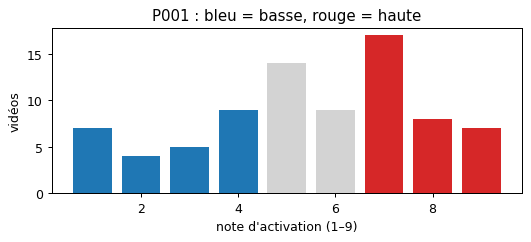

In [4]:
trials = pd.concat([s["trials"] for s in segs.values()], ignore_index=True)
trials = add_arousal_split(trials)
lo, hi = trials.attrs["cuts"][SUBJ]
print(f"Seuils {SUBJ} : basse ≤ {lo:.0f}, haute ≥ {hi:.0f}")
print(trials.groupby("cond").arousal.agg(["count", "min", "max"]))

fig, ax = plt.subplots(figsize=(6, 2.8))
cnt = trials.arousal.value_counts().sort_index()
ax.bar(cnt.index, cnt.values, color=["C0" if v <= lo else "C3" if v >= hi else "lightgrey" for v in cnt.index])
ax.set_xlabel("note d'activation (1–9)"); ax.set_ylabel("vidéos"); ax.set_title(f"{SUBJ} : bleu = basse, rouge = haute")
plt.tight_layout(); plt.show()

## 3. Époques autour des battements

On garde un battement si l'époque entière [−200, +800] ms tient dans la vidéo, si le battement
suivant arrive au moins 600 ms plus tard, et si l'amplitude crête-à-crête reste < 150 µV.
Ligne de base : [−200, −50] ms (avant le QRS).

In [5]:
ep = mne.concatenate_epochs([hep_epochs(s) for s in segs.values()])
ep.metadata = add_arousal_split(ep.metadata.reset_index(drop=True)
                                .merge(trials[["day", "trial", "arousal"]], on=["day", "trial"], suffixes=("_x", ""))
                                .drop(columns="arousal_x"))
ecg_ep = np.vstack([ecg_epochs(segs[d], hep_epochs(segs[d])) for d in DAYS])
meta, times = ep.metadata, ep.times
W = cluster_wave(ep)                       # groupe fronto-central, µV, (époques × temps)
print(f"{len(ep)} époques gardées")
print(meta.groupby("cond").agg(battements=("trial", "size"), videos=("trial", lambda x: x.groupby(meta.day).nunique().sum())))

1200 époques gardées
           battements  videos
cond                         
basse             282      25
haute             337      32
moyenne           270      23
sans note         311      28


## 4. Le HEP moyen (toutes vidéos)

Topographies + courbe du groupe fronto-central (Fz, F1, F2, FCz, FC1, FC2, C1, C2), avec l'ECG moyen
en gris pour voir où tombent l'onde T et le battement suivant.

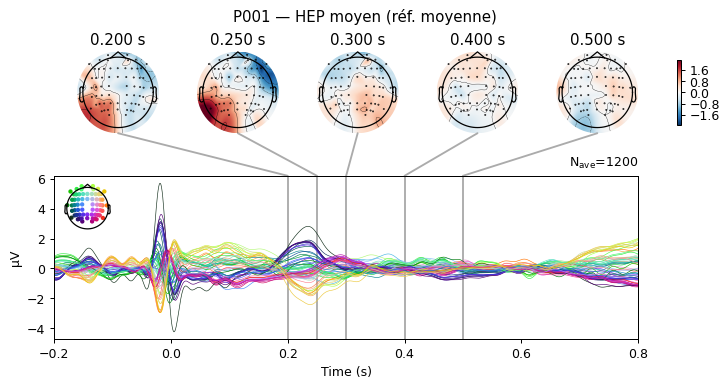

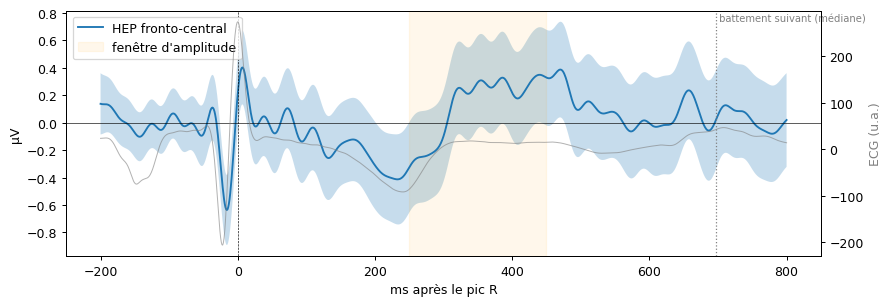

In [6]:
ep.average().plot_joint(times=[0.2, 0.25, 0.3, 0.4, 0.5], title=f"{SUBJ} — HEP moyen (réf. moyenne)")

fig, ax = plt.subplots(figsize=(10, 3.5))
m, se = W.mean(0), W.std(0) / np.sqrt(len(W))
ax.fill_between(times * 1000, m - 1.96 * se, m + 1.96 * se, alpha=.25); ax.plot(times * 1000, m, lw=1.5, label="HEP fronto-central")
ax.axvspan(HEP_WIN[0] * 1000, HEP_WIN[1] * 1000, color="orange", alpha=.08, label="fenêtre d'amplitude")
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5, ls="--")
ax.set_xlabel("ms après le pic R"); ax.set_ylabel("µV"); ax.legend(loc="upper left")
ax2 = ax.twinx(); ax2.plot(times * 1000, ecg_ep.mean(0), color="grey", lw=.8, alpha=.6); ax2.set_ylabel("ECG (u.a.)", color="grey")
nxt = np.median(meta.next_rr_s) * 1000
ax.axvline(nxt, color="grey", ls=":", lw=1); ax.text(nxt, ax.get_ylim()[1] * .9, " battement suivant (médiane)", color="grey", fontsize=8)
plt.tight_layout(); plt.show()

## 5. Haute vs basse

- **Amplitude** : moyenne sur 250–450 ms.
- **Latence** : latence d'**aire fractionnelle 50 %** dans 200–600 ms (instant où l'on atteint la moitié
  de l'aire de la composante dominante), plus robuste au bruit que la latence du pic (donnée aussi).
- **Statistique** : test de permutation en échangeant les étiquettes **par vidéo** (les battements d'une
  même vidéo ne sont pas indépendants) ; erreur-type de la différence de latence par **jackknife**.

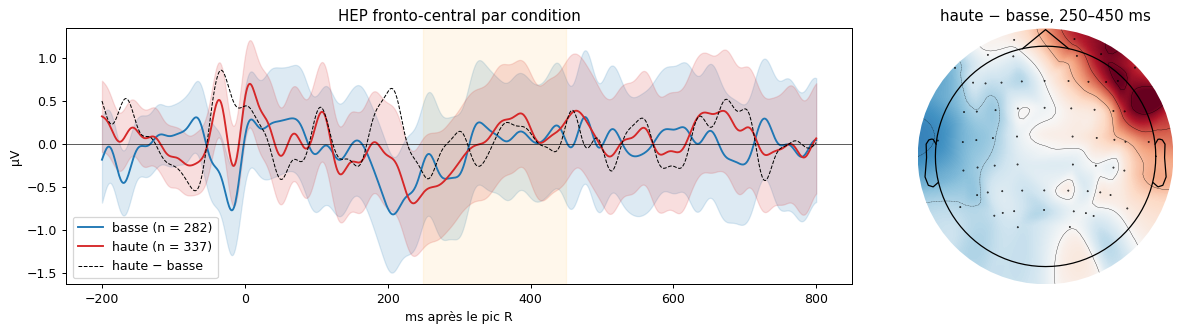

Amplitude : haute − basse = -0.002 µV, p (permutation par vidéo) = 0.997
Latence   : haute − basse = +17 ms, p = 0.885 ; jackknife : +17 ± 288 ms (ET)


,n,amp_uV,lat_50area_s,lat_pic_s
basse,282.0,-0.008,0.238,0.208
haute,337.0,-0.010,0.255,0.236
haute − basse,55.0,-0.002,0.017,0.028


In [7]:
g = meta.cond.to_numpy()
blk = (meta.day.astype(str) + "_" + meta.trial.astype(str)).to_numpy()
sel = np.isin(g, ["basse", "haute"])

fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[2, 1]))
for c, col in [("basse", "C0"), ("haute", "C3")]:
    x = W[g == c]; m, se = x.mean(0), x.std(0) / np.sqrt(len(x))
    axs[0].fill_between(times * 1000, m - 1.96 * se, m + 1.96 * se, color=col, alpha=.15)
    axs[0].plot(times * 1000, m, color=col, label=f"{c} (n = {len(x)})")
d = W[g == "haute"].mean(0) - W[g == "basse"].mean(0)
axs[0].plot(times * 1000, d, color="k", lw=.8, ls="--", label="haute − basse")
axs[0].axvspan(HEP_WIN[0] * 1000, HEP_WIN[1] * 1000, color="orange", alpha=.08)
axs[0].axhline(0, color="k", lw=.5); axs[0].set_xlabel("ms après le pic R"); axs[0].set_ylabel("µV"); axs[0].legend()
axs[0].set_title("HEP fronto-central par condition")

ev_diff = mne.combine_evoked([ep[g == "haute"].average(), ep[g == "basse"].average()], weights=[1, -1])
ev_diff.plot_topomap(times=[np.mean(HEP_WIN)], average=HEP_WIN[1] - HEP_WIN[0], axes=axs[1], colorbar=False, show=False)
axs[1].set_title(f"haute − basse, {HEP_WIN[0]*1000:.0f}–{HEP_WIN[1]*1000:.0f} ms")
plt.tight_layout(); plt.show()

rows = {c: hep_metrics(W[g == c], times) for c in ["basse", "haute"]}
res = pd.DataFrame(rows).T
res.loc["haute − basse"] = res.loc["haute"] - res.loc["basse"]

amp = lambda x: mean_amp(x.mean(0), times)
lat = lambda x: frac_area_latency(x.mean(0), times)
d_amp, p_amp = permutation_test(W[sel], g[sel], amp, n_perm=2000, block=blk[sel])
d_lat, p_lat = permutation_test(W[sel], g[sel], lat, n_perm=2000, block=blk[sel])
jk_d, jk_se = jackknife_latency_diff(W[g == "basse"], W[g == "haute"], times)
print(f"Amplitude : haute − basse = {d_amp:+.3f} µV, p (permutation par vidéo) = {p_amp:.3f}")
print(f"Latence   : haute − basse = {d_lat*1000:+.0f} ms, p = {p_lat:.3f} ; jackknife : {jk_d*1000:+.0f} ± {jk_se*1000:.0f} ms (ET)")
res.round(3)

### Sur tout le scalp : test par clusters (exploratoire)
Comparaison haute vs basse sur toutes les électrodes et tous les instants 0–600 ms, corrigée pour les
comparaisons multiples par clusters. Attention : ici les unités sont les battements (non indépendants au sein
d'une vidéo) : à prendre comme une exploration ; le vrai test sera au niveau du groupe de participants.

In [8]:
from mne.stats import permutation_cluster_test
e2 = ep.copy().crop(0, 0.6).resample(250)
adj, _ = mne.channels.find_ch_adjacency(e2.info, "eeg")
X = [e2[g == c].get_data().transpose(0, 2, 1) * 1e6 for c in ["haute", "basse"]]
F, clusters, pv, _ = permutation_cluster_test(X, n_permutations=500, adjacency=adj, seed=0, out_type="mask", verbose=False)
sig = [(i, p) for i, p in enumerate(pv) if p < 0.05]
print(f"{len(clusters)} clusters, dont {len(sig)} avec p < 0,05")
for i, p in sig:
    tm, chm = np.where(clusters[i])
    print(f"  p = {p:.3f} : {e2.times[tm.min()]*1000:.0f}–{e2.times[tm.max()]*1000:.0f} ms, électrodes {sorted(set(np.array(e2.ch_names)[chm]))}")

C:\Users\ehren\AppData\Local\Temp\ipykernel_25500\2616165198.py:5: RuntimeWarning: Ignoring argument "tail", performing 1-tailed F-test
  F, clusters, pv, _ = permutation_cluster_test(X, n_permutations=500, adjacency=adj, seed=0, out_type="mask", verbose=False)
C:\Users\ehren\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


7 clusters, dont 0 avec p < 0,05


## 6. Contrôles : est-ce vraiment le cerveau ?

1. **L'ECG lui-même** diffère-t-il entre haute et basse ? (Si oui, l'artefact du champ cardiaque peut
   créer une fausse différence de HEP.)
2. **Fréquence cardiaque** : si le cœur bat plus vite en activation haute, l'onde T et le battement
   suivant arrivent plus tôt → ça peut **imiter un changement de latence**.
3. **Faux battements** : mêmes vidéos, mêmes nombres d'instants, mais tirés au hasard. Le « HEP »
   obtenu doit être plat ; sinon on mesure autre chose que la réponse au cœur.

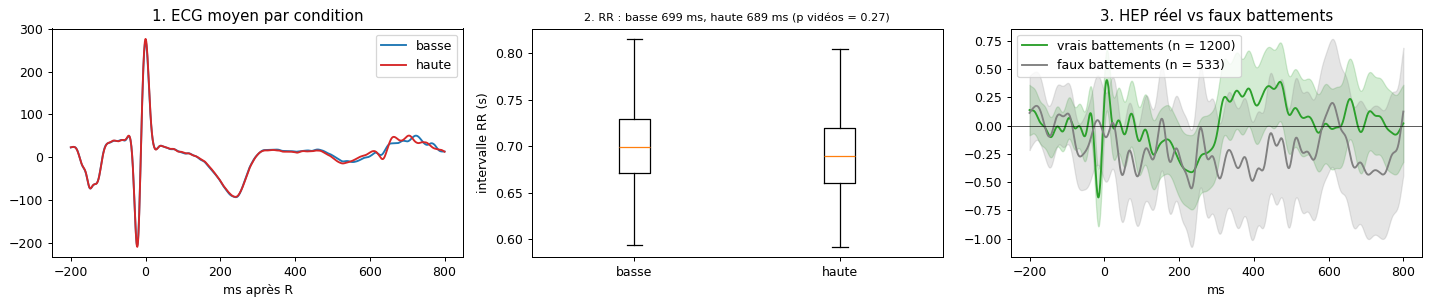

ECG moyen 250–450 ms, haute − basse = -1.18 (u.a.), p = 0.189


In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.5))
for c, col in [("basse", "C0"), ("haute", "C3")]:
    axs[0].plot(times * 1000, ecg_ep[g == c].mean(0), color=col, label=c)
axs[0].set_title("1. ECG moyen par condition"); axs[0].set_xlabel("ms après R"); axs[0].legend()

rr = [meta.rr_s[g == c].dropna() for c in ["basse", "haute"]]
axs[1].boxplot(rr, tick_labels=["basse", "haute"], showfliers=False); axs[1].set_ylabel("intervalle RR (s)")
from scipy.stats import mannwhitneyu
v_rr = meta[sel].groupby(blk[sel]).agg(rr=("rr_s", "mean"), cond=("cond", "first"))
p_rr = mannwhitneyu(v_rr.rr[v_rr.cond == "basse"], v_rr.rr[v_rr.cond == "haute"]).pvalue
axs[1].set_title(f"2. RR : basse {rr[0].median()*1000:.0f} ms, haute {rr[1].median()*1000:.0f} ms (p vidéos = {p_rr:.2f})", fontsize=9)

sur = mne.concatenate_epochs([hep_epochs(s, peaks=surrogate_peaks(s, seed=1)) for s in segs.values()])
Ws = cluster_wave(sur)
for x, lab, col in [(W, "vrais battements", "C2"), (Ws, "faux battements", "grey")]:
    m, se = x.mean(0), x.std(0) / np.sqrt(len(x))
    axs[2].fill_between(times * 1000, m - 1.96 * se, m + 1.96 * se, color=col, alpha=.2); axs[2].plot(times * 1000, m, color=col, label=f"{lab} (n = {len(x)})")
axs[2].axhline(0, color="k", lw=.5); axs[2].legend(); axs[2].set_title("3. HEP réel vs faux battements"); axs[2].set_xlabel("ms")
plt.tight_layout(); plt.show()

ecg_amp = permutation_test(ecg_ep[sel], g[sel], lambda x: x.mean(0)[(times >= HEP_WIN[0]) & (times <= HEP_WIN[1])].mean(),
                           n_perm=2000, block=blk[sel])
print(f"ECG moyen 250–450 ms, haute − basse = {ecg_amp[0]:+.2f} (u.a.), p = {ecg_amp[1]:.3f}")

## 7. Bilan pour P001 et suite

À lire avec les sorties ci-dessus. Points méthodologiques acquis :

- **Électrodes « pouls »** : à détecter systématiquement, elles peuvent fabriquer un HEP de toutes pièces.
- **50 Hz sur l'ECG** : à couper avant `r_peaks` (info utile aussi pour l'étape 1 de Hugo et pour Maroua).
- **ICA cardiaque** (`load_video_session(..., ica=True)`) : testée sur P001, aucune composante ne
  dépasse le seuil (score CTPS max ≈ 0,10 < 0,25) → artefact du champ cardiaque faible chez P001 ;
  à garder comme option pour les autres participants.
- **Notes** : on utilise `labels_train.csv` (80 vidéos notées sur 108 pour P001). Le metadata contient
  aussi des notes pour les 28 autres vidéos, probablement réservées à l'évaluation : on ne s'en sert pas.
- **Un participant ne suffit pas** : la vraie question se tranche au niveau du groupe (une
  différence haute − basse par personne, puis test sur 25–30 participants).

**Suite** : (1) remplacer le découpage provisoire par celui de Micha ; (2) boucler sur 25–30 participants
et faire le test de groupe (amplitude, latence jackknife, clusters) ; (3) ajouter la fréquence cardiaque
comme covariable dans le test de latence.